# ДЗ 1. Рекомендательные системы

Некрылов Леонид

Датасет: **MTS Library** — данные книжного сервиса МТС Библиотека (сейчас МТС Строки) за 2018–2019 годы. Какие книги пользователи начинали читать, сколько прочитали и какую оценку поставили.

Ссылка: https://www.kaggle.com/datasets/sharthz23/mts-library

## Как запустить

1. `pip install -r requirements.txt`
2. Данные скачиваются сами в папку `data/` в ячейке ниже (датасет открытый, логин на Kaggle не нужен). Если не скачалось, можно вручную скачать архив со страницы датасета и распаковать в `data/` (нужны `interactions.csv`, `items.csv`, `users.csv`).
3. Запустить все ячейки по порядку. У меня на ноутбуке (Ryzen 7, без видеокарты) всё считалось примерно 2.5 часа, дольше всего подбор ALS.

Сиды зафиксированы (`SEED = 42`), все параметры фильтрации и разбиения заданы в первой ячейке.

In [1]:
import os
import time
import itertools
import zipfile
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from models import utils, knn, ease, als, fm, timesvdpp

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

DATA = 'data'
MIN_USER = 3
MIN_ITEM = 20
VAL_START = '2019-11-01'
TEST_START = '2019-12-01'
TEST_END = '2020-01-01'
K = 10

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)

In [2]:
def download_data(path):
    if os.path.exists(path + '/interactions.csv'):
        print('data already downloaded')
        return
    os.makedirs(path, exist_ok=True)
    url = 'https://www.kaggle.com/api/v1/datasets/download/sharthz23/mts-library'
    urllib.request.urlretrieve(url, path + '/mts.zip')
    with zipfile.ZipFile(path + '/mts.zip') as z:
        z.extractall(path)
    os.remove(path + '/mts.zip')


download_data(DATA)
inter, items, users = utils.load_data(DATA)
print('interactions', inter.shape)
print('items', items.shape)
print('users', users.shape)

data already downloaded


interactions (1533078, 5)
items (59599, 5)
users (142888, 3)


## 1. Данные

Три таблицы:

* `interactions.csv` — кто какую книгу читал: `user_id`, `item_id`, `progress` (сколько процентов книги прочитано), `rating` (оценка от 1 до 5, ставят не всегда), `start_date` (дата, когда начал читать).
* `items.csv` — книги: `id`, `title`, `genres` (жанры через запятую), `authors`, `year` (год издания).
* `users.csv` — пользователи: `user_id`, `age` (возрастная группа), `sex` (0/1).

Одна строка — пользователь открыл книгу и начал читать. Будем рекомендовать каждому пользователю 10 книг, которые он ещё не читал. **Хорошей рекомендацией считаем книгу, которую пользователь действительно начал читать в тестовом месяце.** Прогресс и оценку в это не включаю: у книг, начатых в конце месяца, прогресс ещё маленький, а оценки есть только у ~19% строк. Правило одно для всех моделей, на чём бы они ни обучались.

In [3]:
inter.head()

,user_id,item_id,progress,rating,start_date
0,126706,14433,80,NaN,2018-01-01
1,127290,140952,58,NaN,2018-01-01
2,66991,198453,89,NaN,2018-01-01
3,46791,83486,23,5.0,2018-01-01
4,79313,188770,88,5.0,2018-01-01


In [4]:
items.head()

,id,title,genres,authors,year
0,128115,Ворон-челобитчик,"Зарубежные детские книги,Сказки,Зарубежная кла...",Михаил Салтыков-Щедрин,1886
1,210979,Скрипка Ротшильда,"Классическая проза,Литература 19 века,Русская ...",Антон Чехов,1894
2,95632,Испорченные дети,"Зарубежная классика,Классическая проза,Литерат...",Михаил Салтыков-Щедрин,1869
3,247906,Странный человек,"Пьесы и драматургия,Литература 19 века",Михаил Лермонтов,1831
4,294280,Господа ташкентцы,"Зарубежная классика,Классическая проза,Литерат...",Михаил Салтыков-Щедрин,1873


In [5]:
users.head()

,user_id,age,sex
0,1,45_54,NaN
1,2,18_24,0.0
2,3,65_inf,0.0
3,4,18_24,0.0
4,5,35_44,0.0


## 2. Анализ данных

### Пропуски и дубликаты

In [6]:
print('пропуски interactions')
print(inter.isna().mean().round(3))
print('пропуски items')
print(items.isna().mean().round(3))
print('пропуски users')
print(users.isna().mean().round(3))
print()
print('полные дубликаты строк:', inter.duplicated().sum())
print('дубликаты пар user-item:', inter.duplicated(['user_id', 'item_id']).sum())
print('пользователей без анкеты:', (~inter['user_id'].drop_duplicates().isin(users['user_id'])).sum())
print('книг без метаданных:', (~inter['item_id'].drop_duplicates().isin(items['id'])).sum())

пропуски interactions
user_id       0.000
item_id       0.000
progress      0.000
rating        0.814
start_date    0.000
dtype: float64
пропуски items
id         0.000
title      0.000
genres     0.001
authors    0.116
year       0.216
dtype: float64
пропуски users
user_id    0.000
age        0.001
sex        0.044
dtype: float64



полные дубликаты строк: 0


дубликаты пар user-item: 80
пользователей без анкеты: 15923
книг без метаданных: 0


In [7]:
print(inter[inter.duplicated(['user_id', 'item_id'], keep=False)].sort_values(['user_id', 'item_id']).head(6))

         user_id  item_id  progress  rating  start_date
235670       523    49329        50     NaN  2018-04-24
322043       523    49329        91     NaN  2018-06-05
538989      2758   113728        56     NaN  2018-09-16
894709      2758   113728        10     NaN  2019-03-04
1157841     4804   114245        99     NaN  2019-07-06
1380056     4804   114245        31     NaN  2019-10-20


В id и датах пропусков нет. Оценка пропущена в 81% строк — оценки ставят редко. У 12% книг нет автора, у 22% нет года. Примерно 16 тыс. пользователей нет в таблице `users.csv`, у них просто не будет возраста и пола.

Есть 80 повторов одной и той же пары пользователь-книга (книгу открыли ещё раз). Оставляю одну строку, где прогресс больше.

### Оценки, прогресс и время

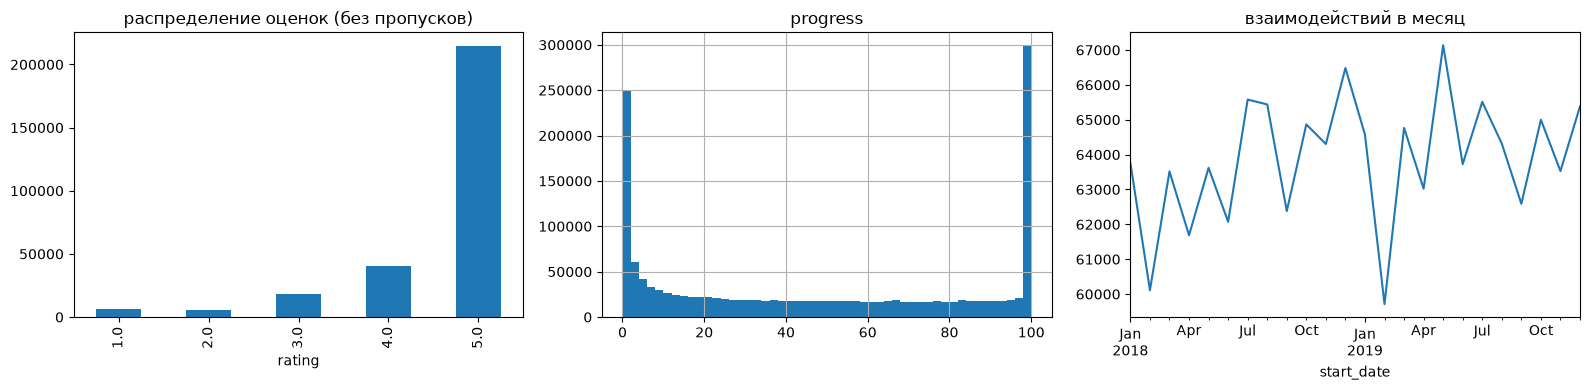

rating
1.0    0.021
2.0    0.021
3.0    0.064
4.0    0.142
5.0    0.752
Name: proportion, dtype: float64
даты: 2018-01-01 - 2019-12-31


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
inter['rating'].value_counts().sort_index().plot.bar(ax=ax[0])
ax[0].set_title('распределение оценок (без пропусков)')
inter['progress'].hist(bins=50, ax=ax[1])
ax[1].set_title('progress')
pd.to_datetime(inter['start_date']).dt.to_period('M').value_counts().sort_index().plot(ax=ax[2])
ax[2].set_title('взаимодействий в месяц')
plt.tight_layout()
plt.show()
print(inter['rating'].value_counts(normalize=True).sort_index().round(3))
print('даты:', inter['start_date'].min(), '-', inter['start_date'].max())

Оценки почти все пятёрки (75%). Прогресс либо маленький (бросили почти сразу), либо около 100 (дочитали). По времени данные идут равномерно с января 2018 по декабрь 2019, примерно 2 тыс. строк в день, резких скачков нет. Значит можно спокойно делить по времени: последние месяцы на проверку.

### Активность пользователей и популярность книг

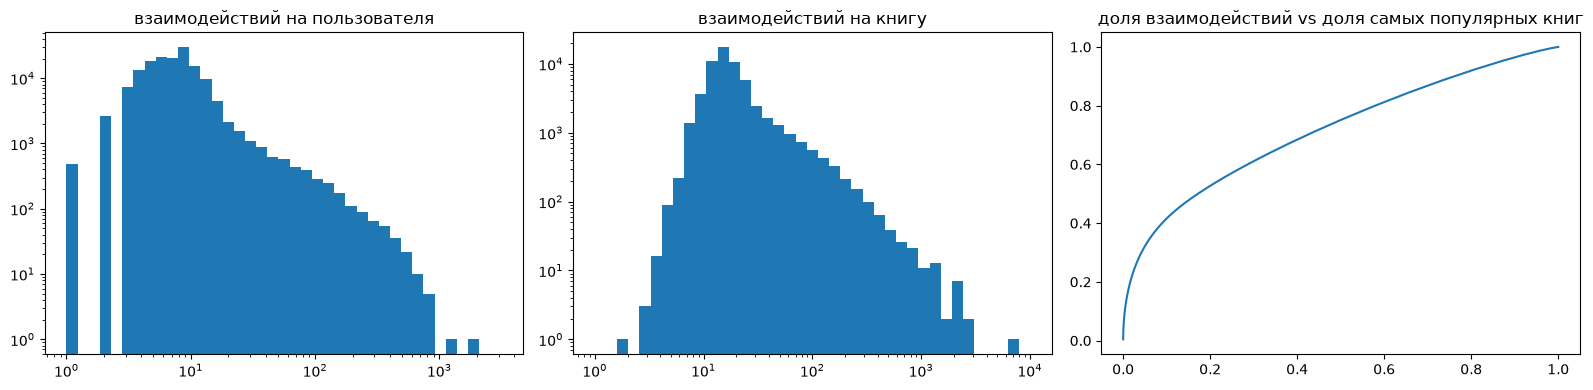

count    151600.0
mean         10.1
std          20.9
min           1.0
25%           5.0
50%           7.0
75%          10.0
max        2091.0
dtype: float64
count    59599.0
mean        25.7
std         60.7
min          2.0
25%         13.0
50%         16.0
75%         21.0
max       6576.0
dtype: float64
sparsity: 0.999830


In [9]:
user_cnt = inter.groupby('user_id').size()
item_cnt = inter.groupby('item_id').size()
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(user_cnt, bins=np.logspace(0, 3.5, 40))
ax[0].set_xscale('log')
ax[0].set_yscale('log')
ax[0].set_title('взаимодействий на пользователя')
ax[1].hist(item_cnt, bins=np.logspace(0, 4, 40))
ax[1].set_xscale('log')
ax[1].set_yscale('log')
ax[1].set_title('взаимодействий на книгу')
s = np.sort(item_cnt.values)[::-1]
ax[2].plot(np.arange(len(s)) / len(s), np.cumsum(s) / s.sum())
ax[2].set_title('доля взаимодействий vs доля самых популярных книг')
plt.tight_layout()
plt.show()
print(user_cnt.describe().round(1))
print(item_cnt.describe().round(1))
print('sparsity: %.6f' % (1 - len(inter) / (inter['user_id'].nunique() * inter['item_id'].nunique())))

Обычно у пользователя 7 книг, у книги 16 читателей. Но есть пользователи с тысячами книг и книги с тысячами читателей. У каждой книги минимум 2 читателя, видимо авторы датасета его уже немного почистили. Матрица пользователь × книга почти пустая (заполнено 0.02%).

### Метаданные

уникальных жанров: 640  жанров у книги в среднем: 2.13
уникальных авторов: 19310
книг с непонятным годом: 12925


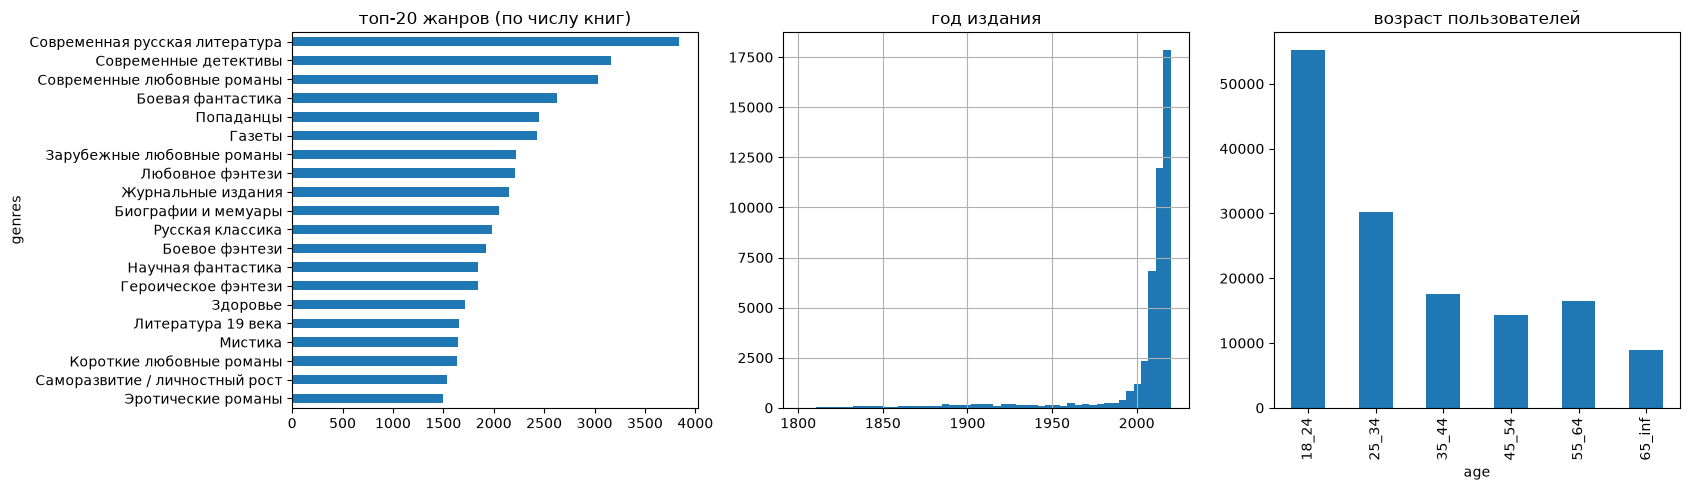

sex
0.0    91991
1.0    44635
NaN     6262
Name: count, dtype: int64


In [10]:
genres = items['genres'].dropna().str.split(',').explode()
authors = items['authors'].dropna().str.split(',').explode()
years = pd.to_numeric(items['year'].astype(str).str[:4], errors='coerce')
print('уникальных жанров:', genres.nunique(), ' жанров у книги в среднем:', round(items['genres'].dropna().str.split(',').apply(len).mean(), 2))
print('уникальных авторов:', authors.nunique())
print('книг с непонятным годом:', years.isna().sum())

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
genres.value_counts().head(20)[::-1].plot.barh(ax=ax[0])
ax[0].set_title('топ-20 жанров (по числу книг)')
years[(years > 1800) & (years < 2021)].hist(bins=50, ax=ax[1])
ax[1].set_title('год издания')
users['age'].value_counts().sort_index().plot.bar(ax=ax[2])
ax[2].set_title('возраст пользователей')
plt.tight_layout()
plt.show()
print(users['sex'].value_counts(dropna=False))

In [11]:
tmp = inter.merge(items[['id', 'genres']], left_on='item_id', right_on='id')
tmp = tmp.assign(genre=tmp['genres'].str.split(',')).explode('genre')
g = tmp.groupby('genre').agg(n=('user_id', 'size'), progress=('progress', 'mean'), rating=('rating', 'mean'))
print(g.sort_values('n', ascending=False).head(15).round(2))
del tmp

                                     n  progress  rating
genre                                                   
Любовное фэнтези                116723     63.38    4.64
Современная русская литература   96920     44.20    4.56
Современные любовные романы      94623     56.02    4.55
Современные детективы            94410     53.52    4.58
Попаданцы                        93403     58.92    4.57
Героическое фэнтези              78117     54.87    4.65
Боевая фантастика                75147     53.04    4.57
Зарубежные любовные романы       71884     53.02    4.54
Саморазвитие / личностный рост   64211     32.81    4.50
Боевое фэнтези                   63154     52.43    4.60
Русская классика                 56176     39.21    4.60
Литература 19 века               52711     37.43    4.61
Эротические романы               49647     57.12    4.52
Зарубежные детективы             49463     45.28    4.60
Триллеры                         48969     44.51    4.59


Жанров 640, у книги в среднем 2 жанра, авторов около 19 тыс. Большая часть книг издана после 2000 года, но есть и классика. Пользователи в основном молодые, 18–34 лет. По жанрам видно, что их читают по-разному: например, любовное фэнтези дочитывают в среднем на 63%, а саморазвитие и русскую классику только на 33–39%. Так что жанр должен помогать модели FM.

### Очистка и подвыборка

1. Удаляю повторы пар пользователь-книга (оставляю строку с большим прогрессом).
2. Оставляю книги, у которых хотя бы 20 читателей, и пользователей, у которых хотя бы 3 книги. Повторяю, пока оба условия не выполнятся сразу (после удаления книг у кого-то может стать меньше 3 книг и наоборот).

Почему так: книг всего 60 тыс., и для EASE нужна матрица 60k × 60k, это около 29 ГБ, не влезает в память. С порогом 20 остаётся ~13 тыс. книг и почти половина всех данных. Пользователи с 1–2 книгами почти ничего не дают моделям. Отбор без случайности, поэтому каждый раз получается одна и та же выборка.

In [12]:
df = utils.drop_dups(inter)
df = utils.filter_core(df, MIN_USER, MIN_ITEM)
df, user_ids, item_ids = utils.encode_ids(df)
n_users, n_items = len(user_ids), len(item_ids)
print('было:  %d взаимодействий, %d пользователей, %d книг' % (len(inter), inter['user_id'].nunique(), inter['item_id'].nunique()))
print('стало: %d взаимодействий, %d пользователей, %d книг' % (len(df), n_users, n_items))
print('оценок осталось:', df['rating'].notna().sum())
print('sparsity: %.5f' % (1 - len(df) / (n_users * n_items)))

было:  1533078 взаимодействий, 151600 пользователей, 59599 книг
стало: 740599 взаимодействий, 87623 пользователей, 13121 книг
оценок осталось: 151981
sparsity: 0.99936


## 3. Как проверяем модели

* **Делим по времени**:
  * для подбора параметров: обучаем на всём до 1 ноября 2019, проверяем на ноябре (validation);
  * для финального сравнения: обучаем на всём до 1 декабря 2019, проверяем на декабре (test).
* **Каких пользователей проверяем**: у кого есть история до этого месяца и кто в этом месяце начал читать хотя бы одну новую книгу. Совсем новых пользователей (без истории) мало, около 300 в месяц, и рекомендовать им по истории нельзя, поэтому их не считаю. Им можно было бы показывать просто популярное.
* **Из чего выбираем**: все книги, которые встречались в обучающей части. Новых книг в проверочных месяцах после фильтрации нет.
* **Уже прочитанное** убираем из рекомендаций. Правильными ответами считаются только новые для пользователя книги.
* **Метрики при K = 10**. Главную выбрал заранее, до подбора: **NDCG@10**. Она учитывает не только угадали или нет, но и на каком месте в списке, а пользователь в первую очередь смотрит на верх списка. Ещё считаю **Recall@10** (какую долю книг, которые человек реально начал читать, мы угадали) и **HitRate@10** (скольким пользователям угадали хотя бы одну книгу). И **Coverage@10** — какая часть каталога вообще попадает в рекомендации, чтобы видеть, не советует ли модель всем одно и то же популярное.

У всех моделей одинаковые пользователи, книги-кандидаты и правильные ответы.

In [13]:
def get_day(date):
    return (pd.Timestamp(date) - pd.Timestamp('2018-01-01')).days


train_val, val = utils.time_split(df, VAL_START, TEST_START)
train_full, test = utils.time_split(df, TEST_START, TEST_END)
val_users, val_targets = utils.get_targets(train_val, val)
test_users, test_targets = utils.get_targets(train_full, test)
VAL_DAY = get_day(VAL_START)
TEST_DAY = get_day(TEST_START)

for name, tr, te, us, tg in [('val', train_val, val, val_users, val_targets), ('test', train_full, test, test_users, test_targets)]:
    print(name)
    print('  train:', len(tr), ' target month:', len(te))
    print('  пользователей для оценки:', len(us), ' целевых пар:', sum(len(v) for v in tg.values()))
    print('  новых пользователей в месяце:', te.loc[~te['uid'].isin(tr['uid']), 'uid'].nunique())
    print('  новых книг в месяце:', (~te['iid'].isin(tr['iid'])).sum())
    print('  среднее число целевых книг на пользователя: %.2f' % np.mean([len(v) for v in tg.values()]))

val
  train: 683514  target month: 27891
  пользователей для оценки: 11467  целевых пар: 26361
  новых пользователей в месяце: 359
  новых книг в месяце: 0
  среднее число целевых книг на пользователя: 2.30
test
  train: 711405  target month: 29194
  пользователей для оценки: 11785  целевых пар: 27652
  новых пользователей в месяце: 298
  новых книг в месяце: 0
  среднее число целевых книг на пользователя: 2.35


## 4. Модели

Главная функция `run(name, params, train, users, day)`: строит матрицу пользователь × книга, обучает нужную модель, считает скоры, убирает прочитанное и возвращает топ-10. Функция `tune` перебирает параметры по сетке на validation и сортирует по NDCG@10. Для сравнения есть простая модель Popular — всем одни и те же самые популярные книги.

Признаки для FM готовлю один раз заранее, подробнее в разделе про FM.

In [14]:
fm_feats = fm.make_features(items, users, item_ids, user_ids, use_meta=True)
fm_feats_ids = fm.make_features(items, users, item_ids, user_ids, use_meta=False)
print('признаков FM с метаданными:', fm_feats['n_feat'], ' только id:', fm_feats_ids['n_feat'])


def run(name, params, train, users_eval, day):
    X = utils.make_matrix(train, n_users, n_items)
    t = time.time()
    if name == 'pop':
        pop = np.asarray(X.sum(0)).ravel()
        score_fn = lambda u: np.tile(pop, (len(u), 1))
    elif name == 'knn':
        W = knn.fit(X, **params)
        score_fn = lambda u: knn.get_scores(W, X, u)
    elif name == 'als':
        model = als.fit(X, **params)
        score_fn = lambda u: als.get_scores(model, u)
    elif name == 'ease':
        B = ease.fit(X, **params)
        score_fn = lambda u: ease.get_scores(B, X, u)
    elif name == 'fm':
        p = dict(params)
        feats = fm_feats if p.pop('use_meta', True) else fm_feats_ids
        model = fm.fit(train, feats, **p)
        score_fn = lambda u: fm.get_scores(model, u)
    elif name == 'tsvd':
        model = timesvdpp.fit(train, n_users, n_items, **params)
        score_fn = lambda u: timesvdpp.get_scores(model, u, day)
    recs = utils.recommend(score_fn, users_eval, X, k=K)
    return recs, time.time() - t


def tune(name, grid, fixed={}):
    keys = list(grid.keys())
    rows = []
    for vals in itertools.product(*[grid[k] for k in keys]):
        params = dict(zip(keys, vals))
        params.update(fixed)
        recs, sec = run(name, params, train_val, val_users, VAL_DAY)
        m = utils.calc_metrics(recs, val_users, val_targets, n_items)
        rows.append({**params, **m, 'time': round(sec, 1)})
        print(name, params, 'ndcg@10 = %.4f' % m['ndcg@10'], '(%.0f s)' % sec)
    return pd.DataFrame(rows).sort_values('ndcg@10', ascending=False).reset_index(drop=True)


def get_best(res, keys):
    best = {}
    for k in keys:
        v = res.loc[0, k]
        best[k] = v.item() if hasattr(v, 'item') else v
    return best


best_params = {}
val_results = {}

признаков FM с метаданными: 102871  только id: 100745


In [15]:
recs, sec = run('pop', {}, train_val, val_users, VAL_DAY)
m = utils.calc_metrics(recs, val_users, val_targets, n_items)
val_results['Popular'] = m
best_params['Popular'] = ('pop', {})
print(m)

{'ndcg@10': np.float64(0.006716302974047962), 'recall@10': np.float64(0.01403092193136118), 'hitrate@10': np.float64(0.027818958751199094), 'coverage@10': 0.0019053425805959912}


### 4.1 Item-based kNN

Матрица $X$ из нулей и единиц (1 — пользователь читал книгу). Похожесть двух книг — косинус, плюс в знаменатель добавляю $h$, чтобы книги с парой общих читателей не считались очень похожими:

$$s_{ij} = \frac{|U_i \cap U_j|}{\sqrt{|U_i|\,|U_j|} + h}$$

где $U_i$ — кто читал книгу $i$. Для каждой книги оставляю $k$ самых похожих. Скор книги $i$ для пользователя — сумма похожестей с книгами, которые он уже читал (если они попали в соседи $i$):

$$\hat r_{ui} = \sum_{j \in I_u,\; j \in N_k(i)} s_{ji}$$

Сетка: $k \in \{20, 50, 100, 200, 500\}$, $h \in \{0, 10, 50\}$.

In [16]:
res_knn = tune('knn', {'k': [20, 50, 100, 200, 500], 'shrink': [0, 10, 50]})
best_params['ItemKNN'] = ('knn', get_best(res_knn, ['k', 'shrink']))
val_results['ItemKNN'] = res_knn.loc[0, ['ndcg@10', 'recall@10', 'hitrate@10', 'coverage@10']].to_dict()
res_knn

knn {'k': 20, 'shrink': 0} ndcg@10 = 0.0142 (9 s)


knn {'k': 20, 'shrink': 10} ndcg@10 = 0.0140 (8 s)


knn {'k': 20, 'shrink': 50} ndcg@10 = 0.0146 (8 s)


knn {'k': 50, 'shrink': 0} ndcg@10 = 0.0140 (8 s)


knn {'k': 50, 'shrink': 10} ndcg@10 = 0.0140 (7 s)


...

knn {'k': 200, 'shrink': 50} ndcg@10 = 0.0140 (10 s)


knn {'k': 500, 'shrink': 0} ndcg@10 = 0.0136 (12 s)


knn {'k': 500, 'shrink': 10} ndcg@10 = 0.0136 (11 s)


knn {'k': 500, 'shrink': 50} ndcg@10 = 0.0137 (9 s)


,k,shrink,ndcg@10,recall@10,hitrate@10,coverage@10,time
0,20,50,0.014633,0.019676,0.041162,0.900160,7.9
1,50,50,0.014575,0.019951,0.041685,0.862434,9.6
2,100,50,0.014464,0.019523,0.042121,0.824327,11.1
3,20,0,0.014155,0.018968,0.040987,0.930493,8.8
4,50,0,0.014047,0.018713,0.040813,0.897569,8.2
5,20,10,0.014038,0.019138,0.040464,0.922719,7.7
6,200,50,0.013988,0.018183,0.040638,0.791784,10.2
7,50,10,0.013982,0.018825,0.040377,0.880878,7.5
8,100,10,0.013875,0.018415,0.040290,0.859005,10.0
9,100,0,0.013813,0.017973,0.039243,0.878058,11.3


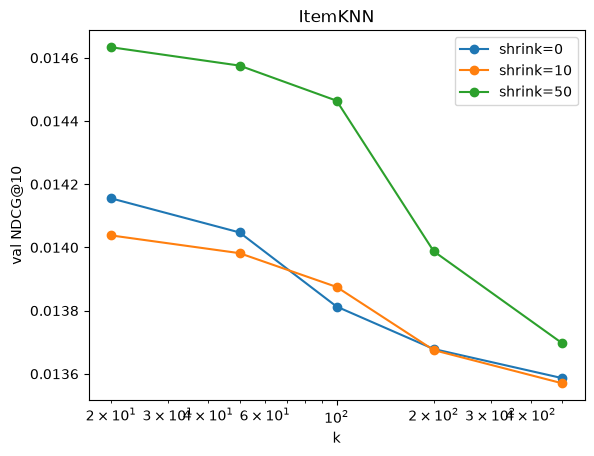

In [17]:
for sh in [0, 10, 50]:
    r = res_knn[res_knn['shrink'] == sh].sort_values('k')
    plt.plot(r['k'], r['ndcg@10'], marker='o', label='shrink=%d' % sh)
plt.xscale('log')
plt.xlabel('k')
plt.ylabel('val NDCG@10')
plt.legend()
plt.title('ItemKNN')
plt.show()

### 4.2 iALS (ALS для неявных данных)

Оценок мало, зато есть факт чтения, поэтому беру ALS для неявных данных (Hu, Koren, Volinsky, 2008). $p_{ui} = 1$, если пользователь читал книгу, иначе 0. Вес ошибки $c_{ui} = 1 + \alpha r_{ui}$: на прочитанных книгах ошибаться «дороже».

$$\min_{x, y} \sum_{u,i} c_{ui} (p_{ui} - x_u^T y_i)^2 + \lambda \Big(\sum_u \|x_u\|^2 + \sum_i \|y_i\|^2\Big)$$

Если зафиксировать векторы книг $Y$, вектор пользователя находится точно:

$$x_u = \big(Y^TY + Y^T(C_u - I)Y + \lambda I\big)^{-1} Y^T C_u p_u$$

и так же для книг. Чередую эти шаги. Скор $\hat r_{ui} = x_u^T y_i$.

Сетка в два шага, чтобы не перебирать всё сразу (ALS считается долго): сначала $\alpha \in \{3, 10, 30\}$ и $\lambda \in \{0.1, 1, 10\}$ при 64 факторах и 8 итерациях, потом число факторов 32 и 128 при лучших $\alpha, \lambda$.

In [18]:
res_als = tune('als', {'alpha': [3.0, 10.0, 30.0], 'reg': [0.1, 1.0, 10.0]}, fixed={'factors': 64, 'iters': 8})
res_als

als {'alpha': 3.0, 'reg': 0.1, 'factors': 64, 'iters': 8} ndcg@10 = 0.0132 (104 s)


als {'alpha': 3.0, 'reg': 1.0, 'factors': 64, 'iters': 8} ndcg@10 = 0.0132 (122 s)


als {'alpha': 3.0, 'reg': 10.0, 'factors': 64, 'iters': 8} ndcg@10 = 0.0132 (120 s)


als {'alpha': 10.0, 'reg': 0.1, 'factors': 64, 'iters': 8} ndcg@10 = 0.0134 (125 s)


als {'alpha': 10.0, 'reg': 1.0, 'factors': 64, 'iters': 8} ndcg@10 = 0.0133 (117 s)


als {'alpha': 10.0, 'reg': 10.0, 'factors': 64, 'iters': 8} ndcg@10 = 0.0134 (92 s)


als {'alpha': 30.0, 'reg': 0.1, 'factors': 64, 'iters': 8} ndcg@10 = 0.0126 (106 s)


als {'alpha': 30.0, 'reg': 1.0, 'factors': 64, 'iters': 8} ndcg@10 = 0.0126 (113 s)


als {'alpha': 30.0, 'reg': 10.0, 'factors': 64, 'iters': 8} ndcg@10 = 0.0127 (120 s)


,alpha,reg,factors,iters,ndcg@10,recall@10,hitrate@10,coverage@10,time
0,10.0,0.1,64,8,0.013426,0.021486,0.044999,0.176206,124.8
1,10.0,10.0,64,8,0.013392,0.021411,0.045260,0.170642,92.4
2,10.0,1.0,64,8,0.013292,0.021016,0.044301,0.176130,116.5
3,3.0,1.0,64,8,0.013237,0.020558,0.043167,0.134517,122.4
4,3.0,0.1,64,8,0.013208,0.020489,0.043080,0.134670,103.9
5,3.0,10.0,64,8,0.013153,0.020590,0.042557,0.130402,119.9
6,30.0,10.0,64,8,0.012730,0.019669,0.042906,0.230394,120.1
7,30.0,1.0,64,8,0.012637,0.019345,0.042557,0.232223,112.6
8,30.0,0.1,64,8,0.012627,0.019829,0.043429,0.230394,105.8


In [19]:
b = get_best(res_als, ['alpha', 'reg'])
res_als2 = tune('als', {'factors': [32, 128]}, fixed={'alpha': b['alpha'], 'reg': b['reg'], 'iters': 8})
res_als_all = pd.concat([res_als, res_als2]).sort_values('ndcg@10', ascending=False).reset_index(drop=True)
best_params['iALS'] = ('als', get_best(res_als_all, ['factors', 'alpha', 'reg', 'iters']))
val_results['iALS'] = res_als_all.loc[0, ['ndcg@10', 'recall@10', 'hitrate@10', 'coverage@10']].to_dict()
res_als_all

als {'factors': 32, 'alpha': 10.0, 'reg': 0.1, 'iters': 8} ndcg@10 = 0.0122 (74 s)


als {'factors': 128, 'alpha': 10.0, 'reg': 0.1, 'iters': 8} ndcg@10 = 0.0132 (5604 s)


,alpha,reg,factors,iters,ndcg@10,recall@10,hitrate@10,coverage@10,time
0,10.0,0.1,64,8,0.013426,0.021486,0.044999,0.176206,124.8
1,10.0,10.0,64,8,0.013392,0.021411,0.045260,0.170642,92.4
2,10.0,1.0,64,8,0.013292,0.021016,0.044301,0.176130,116.5
3,3.0,1.0,64,8,0.013237,0.020558,0.043167,0.134517,122.4
4,3.0,0.1,64,8,0.013208,0.020489,0.043080,0.134670,103.9
5,10.0,0.1,128,8,0.013155,0.019742,0.042993,0.282372,5604.3
6,3.0,10.0,64,8,0.013153,0.020590,0.042557,0.130402,119.9
7,30.0,10.0,64,8,0.012730,0.019669,0.042906,0.230394,120.1
8,30.0,1.0,64,8,0.012637,0.019345,0.042557,0.232223,112.6
9,30.0,0.1,64,8,0.012627,0.019829,0.043429,0.230394,105.8


### 4.3 EASE (Steck, 2019)

Простая линейная модель: каждую книгу предсказываем через остальные книги пользователя, $X \approx XB$. Чтобы модель не выучила просто $B = I$ (книга предсказывает сама себя), диагональ $B$ запрещена:

$$\min_B \|X - XB\|_F^2 + \lambda \|B\|_F^2, \quad \text{diag}(B) = 0$$

Решается формулой: $P = (X^TX + \lambda I)^{-1}$, $B_{ij} = -P_{ij} / P_{jj}$, на диагонали 0. Скор $\hat r_u = x_u B$.

Сетка: $\lambda \in \{100, 250, 500, 1000, 2000, 5000\}$.

ease {'lam': 100} ndcg@10 = 0.0176 (45 s)


ease {'lam': 250} ndcg@10 = 0.0171 (40 s)


ease {'lam': 500} ndcg@10 = 0.0166 (40 s)


ease {'lam': 1000} ndcg@10 = 0.0161 (40 s)


ease {'lam': 2000} ndcg@10 = 0.0153 (40 s)


ease {'lam': 5000} ndcg@10 = 0.0143 (40 s)


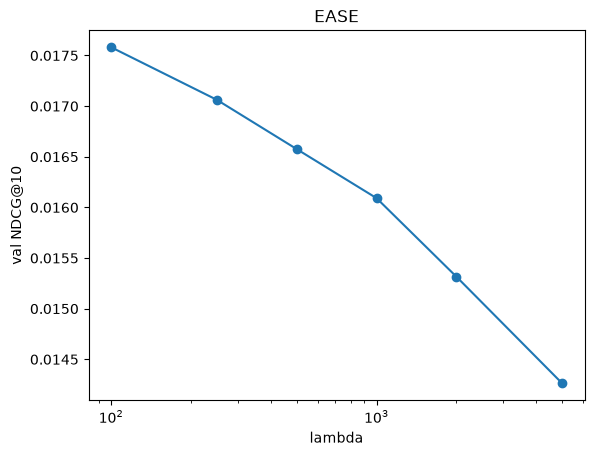

,lam,ndcg@10,recall@10,hitrate@10,coverage@10,time
0,100,0.017581,0.024780,0.053022,0.700175,45.3
1,250,0.017063,0.024596,0.051975,0.671290,39.7
2,500,0.016576,0.023959,0.051278,0.655285,39.7
3,1000,0.016091,0.023875,0.050406,0.637528,40.4
4,2000,0.015315,0.022888,0.047964,0.623352,39.7
5,5000,0.014264,0.021472,0.045784,0.607271,40.0


In [20]:
res_ease = tune('ease', {'lam': [100, 250, 500, 1000, 2000, 5000]})
best_params['EASE'] = ('ease', get_best(res_ease, ['lam']))
val_results['EASE'] = res_ease.loc[0, ['ndcg@10', 'recall@10', 'hitrate@10', 'coverage@10']].to_dict()
r = res_ease.sort_values('lam')
plt.plot(r['lam'], r['ndcg@10'], marker='o')
plt.xscale('log')
plt.xlabel('lambda')
plt.ylabel('val NDCG@10')
plt.title('EASE')
plt.show()
res_ease

### 4.4 Факторизационная машина (FM) с признаками

Признаки:

* пользователь: id, возрастная группа, пол;
* книга: id, жанры (если жанров несколько, каждый с весом $1/n$), авторы (только те, у кого в каталоге хотя бы 2 книги, тоже с весом $1/n$), год издания по группам (до 1900, 1900–1990, 1990–2005, 2005–2012, 2012–2016, 2016+, неизвестно).

Почему такие: книги в основном выбирают по жанру и автору, и через них редкая книга «связывается» с похожими популярными. Год отличает классику от новинок. От возраста и пола зависит, какие жанры человек читает (детские книги, любовные романы и т.д.). Всё это известно в момент рекомендации: данные о книге не меняются, анкету заполняют при регистрации. Ничего из будущего (прогресс, оценки, популярность после даты разбиения) не используется.

Модель (Rendle, 2010):

$$\hat y(x) = w_0 + \sum_i w_i x_i + \sum_{i<j} \langle v_i, v_j \rangle x_i x_j$$

Попарную часть можно посчитать быстро: $\frac12 \sum_f \big[(\sum_i v_{if} x_i)^2 - \sum_i v_{if}^2 x_i^2\big]$.

Обучаю через BPR: берём пару (пользователь, прочитанная книга $i$) и случайную книгу $j$, и хотим, чтобы прочитанная получила скор больше:

$$-\ln \sigma(\hat y(u, i) - \hat y(u, j)) + \lambda \|\cdot\|^2$$

Adam, lr = 0.003, батч 8192, 8 эпох.

Сетка: размер векторов 32 или 64, $\lambda \in \{10^{-5}, 10^{-4}, 10^{-3}\}$. Чтобы понять, помогают ли признаки, лучшую конфигурацию ещё обучаю только на id пользователя и книги.

In [21]:
res_fm = tune('fm', {'dim': [32, 64], 'reg': [1e-5, 1e-4, 1e-3]}, fixed={'epochs': 8})
best_params['FM'] = ('fm', get_best(res_fm, ['dim', 'reg', 'epochs']))
val_results['FM'] = res_fm.loc[0, ['ndcg@10', 'recall@10', 'hitrate@10', 'coverage@10']].to_dict()
res_fm

fm {'dim': 32, 'reg': 1e-05, 'epochs': 8} ndcg@10 = 0.0139 (67 s)


fm {'dim': 32, 'reg': 0.0001, 'epochs': 8} ndcg@10 = 0.0138 (61 s)


fm {'dim': 32, 'reg': 0.001, 'epochs': 8} ndcg@10 = 0.0147 (61 s)


fm {'dim': 64, 'reg': 1e-05, 'epochs': 8} ndcg@10 = 0.0122 (87 s)


fm {'dim': 64, 'reg': 0.0001, 'epochs': 8} ndcg@10 = 0.0123 (86 s)


fm {'dim': 64, 'reg': 0.001, 'epochs': 8} ndcg@10 = 0.0133 (76 s)


,dim,reg,epochs,ndcg@10,recall@10,hitrate@10,coverage@10,time
0,32,0.00100,8,0.014712,0.022196,0.045435,0.062114,61.5
1,32,0.00001,8,0.013915,0.020938,0.043865,0.068973,66.7
2,32,0.00010,8,0.013751,0.020790,0.043516,0.067906,61.2
3,64,0.00100,8,0.013264,0.020682,0.044388,0.098544,76.1
4,64,0.00010,8,0.012257,0.019376,0.041510,0.111501,85.9
5,64,0.00001,8,0.012231,0.019141,0.041336,0.112491,86.7


In [22]:
p = dict(best_params['FM'][1])
p['use_meta'] = False
best_params['FM (только id)'] = ('fm', p)
recs, sec = run('fm', p, train_val, val_users, VAL_DAY)
val_results['FM (только id)'] = utils.calc_metrics(recs, val_users, val_targets, n_items)
print(val_results['FM'])
print(val_results['FM (только id)'])

{'ndcg@10': 0.01471191137403891, 'recall@10': 0.02219630008664814, 'hitrate@10': 0.04543472573471701, 'coverage@10': 0.062114168127429314}
{'ndcg@10': np.float64(0.008891513482953665), 'recall@10': np.float64(0.01423827978460148), 'hitrate@10': np.float64(0.03435946629458446), 'coverage@10': 0.10586083377791326}


### 4.5 timeSVD++ (Koren, 2009)

Эта модель предсказывает оценку (1–5) и учитывает время. Учу на строках, где есть оценка. В $N(u)$ кладу все книги, которые пользователь открывал (даже без оценки), — в SVD++ это как раз отдельная часть модели:

$$\hat r_{ui}(t) = \mu + b_i + b_{i,\text{Bin}(t)} + b_u + \alpha_u \,\text{dev}_u(t) + b_{u,t} + q_i^T\Big(p_u + \alpha^p_u\, \text{dev}_u(t) + |N(u)|^{-1/2}\sum_{j\in N(u)} y_j\Big)$$

Что тут от времени:

* $b_{i,\text{Bin}(t)}$ — популярность книги меняется со временем, время разбито на 30 кусков примерно по 24 дня;
* $\text{dev}_u(t) = \text{sign}(t - t_u)\,|t - t_u|^{0.4}$, где $t_u$ — средний день оценок пользователя; $\alpha_u$ и $\alpha^p_u$ отвечают за то, как со временем меняются его оценки и вкусы;
* $b_{u,t}$ — сдвиг оценок пользователя в конкретный день. Для будущих дней он неизвестен, поэтому при предсказании равен 0.

Обучаю MSE + L2, Adam, lr = 0.003. Рекомендации — 10 книг с самой высокой предсказанной оценкой на первый день проверочного месяца. Параметры выбираю по NDCG@10, а не по RMSE, потому что нам нужен хороший топ, а не точные оценки.

Сетка: размер векторов 16 или 64, $\lambda \in \{0.01, 0.1\}$, эпох 5 или 15. Чтобы понять, помогает ли время, лучшую конфигурацию ещё обучаю без временных частей (обычный SVD++).

In [23]:
res_tsvd = tune('tsvd', {'dim': [16, 64], 'reg': [0.01, 0.1], 'epochs': [5, 15]})
best_params['timeSVD++'] = ('tsvd', get_best(res_tsvd, ['dim', 'reg', 'epochs']))
val_results['timeSVD++'] = res_tsvd.loc[0, ['ndcg@10', 'recall@10', 'hitrate@10', 'coverage@10']].to_dict()
res_tsvd

tsvd {'dim': 16, 'reg': 0.01, 'epochs': 5} ndcg@10 = 0.0010 (35 s)


tsvd {'dim': 16, 'reg': 0.01, 'epochs': 15} ndcg@10 = 0.0004 (100 s)


tsvd {'dim': 16, 'reg': 0.1, 'epochs': 5} ndcg@10 = 0.0006 (34 s)


tsvd {'dim': 16, 'reg': 0.1, 'epochs': 15} ndcg@10 = 0.0005 (98 s)


tsvd {'dim': 64, 'reg': 0.01, 'epochs': 5} ndcg@10 = 0.0006 (69 s)


tsvd {'dim': 64, 'reg': 0.01, 'epochs': 15} ndcg@10 = 0.0006 (202 s)


tsvd {'dim': 64, 'reg': 0.1, 'epochs': 5} ndcg@10 = 0.0006 (69 s)


tsvd {'dim': 64, 'reg': 0.1, 'epochs': 15} ndcg@10 = 0.0005 (202 s)


,dim,reg,epochs,ndcg@10,recall@10,hitrate@10,coverage@10,time
0,16,0.01,5,0.000994,0.001642,0.004012,0.265986,34.6
1,16,0.10,5,0.000639,0.001108,0.003227,0.242817,34.4
2,64,0.01,5,0.000594,0.001250,0.002791,0.309961,69.4
3,64,0.10,5,0.000585,0.001182,0.002965,0.289917,69.1
4,64,0.01,15,0.000558,0.000972,0.003227,0.270940,201.9
5,16,0.10,15,0.000533,0.000988,0.002355,0.169957,97.9
6,64,0.10,15,0.000501,0.000693,0.002703,0.237787,202.0
7,16,0.01,15,0.000436,0.000789,0.002180,0.196708,99.9


In [24]:
val_r = val[val['rating'].notna() & val['uid'].isin(train_val['uid'])]
rmse = {}
for label, use_time in [('timeSVD++', True), ('SVD++ (без времени)', False)]:
    p = dict(best_params['timeSVD++'][1])
    p['use_time'] = use_time
    model = timesvdpp.fit(train_val, n_users, n_items, **p)
    pred = timesvdpp.predict_ratings(model, val_r)
    rmse[label] = np.sqrt(np.mean((pred - val_r['rating'].values) ** 2))
    if not use_time:
        best_params[label] = ('tsvd', p)
        X = utils.make_matrix(train_val, n_users, n_items)
        recs = utils.recommend(lambda u: timesvdpp.get_scores(model, u, VAL_DAY), val_users, X, k=K)
        val_results[label] = utils.calc_metrics(recs, val_users, val_targets, n_items)
rmse['константа mu'] = np.sqrt(np.mean((train_val['rating'].mean() - val_r['rating'].values) ** 2))
print('RMSE на оценках validation:', {k: round(v, 4) for k, v in rmse.items()})
print(val_results['timeSVD++'])
print(val_results['SVD++ (без времени)'])

RMSE на оценках validation: {'timeSVD++': np.float64(0.7456), 'SVD++ (без времени)': np.float64(0.6977), 'константа mu': np.float64(0.7035)}
{'ndcg@10': 0.0009943126058847443, 'recall@10': 0.0016416629519959277, 'hitrate@10': 0.004011511293276359, 'coverage@10': 0.2659858242512004}
{'ndcg@10': np.float64(0.0016480514321889478), 'recall@10': np.float64(0.002299576780032985), 'hitrate@10': np.float64(0.004970785732972879), 'coverage@10': 0.34151360414602544}


## 5. Сравнение на test

Каждую модель с лучшими параметрами заново обучаю на всём до 1 декабря 2019 и проверяю на декабре.

In [25]:
rows = []
test_recs = {}
for label, (name, params) in best_params.items():
    recs, sec = run(name, params, train_full, test_users, TEST_DAY)
    test_recs[label] = recs
    m = utils.calc_metrics(recs, test_users, test_targets, n_items)
    rows.append({'model': label, **{k: round(v, 4) for k, v in m.items()},
                 'val ndcg@10': round(val_results[label]['ndcg@10'], 4),
                 'params': params, 'time, s': round(sec, 1)})
    print(label, m)
final = pd.DataFrame(rows).sort_values('ndcg@10', ascending=False).reset_index(drop=True)
final

Popular {'ndcg@10': np.float64(0.0034338711150634), 'recall@10': np.float64(0.006140178117267638), 'hitrate@10': np.float64(0.012388629613915994), 'coverage@10': 0.0018291288773721515}


ItemKNN {'ndcg@10': np.float64(0.015414203364163005), 'recall@10': np.float64(0.01980762351671822), 'hitrate@10': np.float64(0.04395417904115401), 'coverage@10': 0.9147168660925235}


iALS {'ndcg@10': np.float64(0.01199213647038619), 'recall@10': np.float64(0.016808800977212983), 'hitrate@10': np.float64(0.04039032668646585), 'coverage@10': 0.17651093666641263}


EASE {'ndcg@10': np.float64(0.016542588230853698), 'recall@10': np.float64(0.02282124224479844), 'hitrate@10': np.float64(0.052524395417904116), 'coverage@10': 0.7203719228717324}


FM {'ndcg@10': np.float64(0.007989849528665391), 'recall@10': np.float64(0.012287272004835613), 'hitrate@10': np.float64(0.03071701315231226), 'coverage@10': 0.06455300663059219}


FM (только id) {'ndcg@10': np.float64(0.008272492348610935), 'recall@10': np.float64(0.012520245892180638), 'hitrate@10': np.float64(0.031226134917267712), 'coverage@10': 0.11180550262937276}


timeSVD++ {'ndcg@10': np.float64(0.0022565015995929644), 'recall@10': np.float64(0.0035304373298701503), 'hitrate@10': np.float64(0.007297411964361476), 'coverage@10': 0.24388385031628687}


SVD++ (без времени) {'ndcg@10': np.float64(0.0018005701378147863), 'recall@10': np.float64(0.00301528215199632), 'hitrate@10': np.float64(0.006109461179465422), 'coverage@10': 0.34113253562990625}


,model,ndcg@10,recall@10,hitrate@10,coverage@10,val ndcg@10,params,"time, s"
0,EASE,0.0165,0.0228,0.0525,0.7204,0.0176,{'lam': 100},40.5
1,ItemKNN,0.0154,0.0198,0.0440,0.9147,0.0146,"{'k': 20, 'shrink': 50}",10.0
2,iALS,0.0120,0.0168,0.0404,0.1765,0.0134,"{'factors': 64, 'alpha': 10.0, 'reg': 0.1, 'it...",112.9
3,FM (только id),0.0083,0.0125,0.0312,0.1118,0.0089,"{'dim': 32, 'reg': 0.001, 'epochs': 8, 'use_me...",25.1
4,FM,0.0080,0.0123,0.0307,0.0646,0.0147,"{'dim': 32, 'reg': 0.001, 'epochs': 8}",63.8
5,Popular,0.0034,0.0061,0.0124,0.0018,0.0067,{},2.0
6,timeSVD++,0.0023,0.0035,0.0073,0.2439,0.0010,"{'dim': 16, 'reg': 0.01, 'epochs': 5}",37.3
7,SVD++ (без времени),0.0018,0.0030,0.0061,0.3411,0.0016,"{'dim': 16, 'reg': 0.01, 'epochs': 5, 'use_tim...",28.8


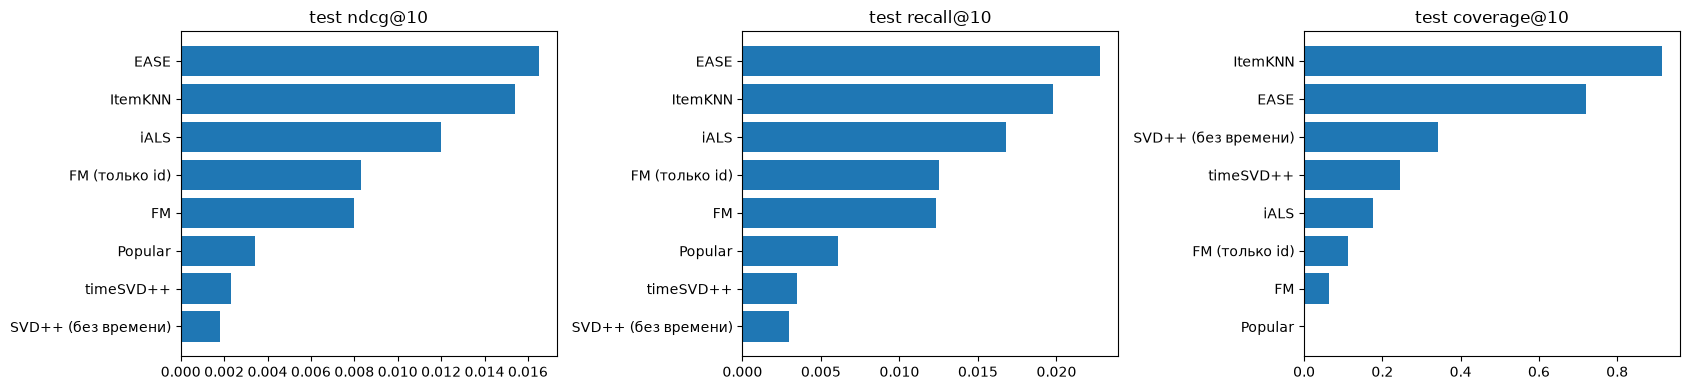

In [26]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for a, metric in zip(ax, ['ndcg@10', 'recall@10', 'coverage@10']):
    f = final.sort_values(metric)
    a.barh(f['model'], f[metric])
    a.set_title('test ' + metric)
plt.tight_layout()
plt.show()

In [27]:
titles = items.set_index('id')['title']
u = test_users[5]
hist = train_full[train_full['uid'] == u].sort_values('day')
print('история пользователя (последние 10):')
print(titles.reindex(item_ids[hist['iid'].values[-10:]]).values)
print('прочитал в декабре:')
print(titles.reindex(item_ids[list(test_targets[u])]).values)
for label in ['EASE', 'FM', 'timeSVD++']:
    print(label, titles.reindex(item_ids[test_recs[label][5]]).values[:5])

история пользователя (последние 10):
<StringArray>
['Дмитрий Донской. Пробуждение силы', 'Мантикора и Дракон. Эпизод II', 'Воплощенное совершенство']
Length: 3, dtype: str
прочитал в декабре:
<StringArray>
['Богатый папа, бедный папа. Роберт Кийосаки (обзор)']
Length: 1, dtype: str
EASE <StringArray>
['Дмитрий Донской. Империя Русь', 'Мантикора и Дракон: Вернуться и вернуть. Эпизод I', 'Роковое очарование', 'Лжедмитрий. Новая заря', 'Согласна на все']
Length: 5, dtype: str
FM <StringArray>
['Сила подсознания, или Как изменить жизнь за 4 недели', 'Самая таинственная тайна и другие сюжеты', 'Яблоки из сада Шлицбутера', 'Черновик', 'Благородный соблазнитель']
Length: 5, dtype: str
timeSVD++ <StringArray>
['Кавказский пленник', 'Ледяные боги', 'Темная империя. Книга третья', 'Букет прекрасных дам', 'Ветер и искры (сборник)']
Length: 5, dtype: str


## 6. Выводы

Итоговые результаты на test (декабрь 2019, 11 785 пользователей):

| модель | NDCG@10 | Recall@10 | HitRate@10 | Coverage@10 | лучшие параметры |
|---|---|---|---|---|---|
| EASE | **0.0165** | **0.0228** | **0.0525** | 0.72 | lam = 100 |
| ItemKNN | 0.0154 | 0.0198 | 0.0440 | 0.91 | k = 20, shrink = 50 |
| iALS | 0.0120 | 0.0168 | 0.0404 | 0.18 | 64 фактора, alpha = 10, reg = 0.1, 8 итераций |
| FM (только id) | 0.0083 | 0.0125 | 0.0312 | 0.11 | dim = 32, reg = 0.001, 8 эпох |
| FM (с признаками) | 0.0080 | 0.0123 | 0.0307 | 0.06 | dim = 32, reg = 0.001, 8 эпох |
| Popular | 0.0034 | 0.0061 | 0.0124 | 0.002 | — |
| timeSVD++ | 0.0023 | 0.0035 | 0.0073 | 0.24 | dim = 16, reg = 0.01, 5 эпох |
| SVD++ (без времени) | 0.0018 | 0.0030 | 0.0061 | 0.34 | те же |

**Что получилось лучше всего.** Лучшая модель — EASE, она первая по всем трём метрикам точности и при этом рекомендует довольно разные книги (72% каталога). Сразу за ней простой ItemKNN, у него самое большое покрытие (91%). Обе модели работают по принципу «книги, похожие на те, что ты уже читал». Для книг это логично: люди часто читают следующую книгу из той же серии или того же автора (это видно и на примере пользователя выше — EASE советует продолжения «Дмитрия Донского» и «Мантикоры и Дракона»). Тройка лучших (EASE, ItemKNN, iALS) одна и та же на validation и на test, то есть параметры, подобранные на ноябре, нормально сработали и на декабре. Сильно поменялось место только у FM, про это ниже.

**Про параметры.** EASE лучше всего работает с маленькой регуляризацией (lam = 100), чем она больше, тем хуже. У kNN лучше мало соседей (k = 20) и shrink = 50, который не даёт считать похожими книги с парой общих читателей. У iALS важнее всего оказалась alpha: при 10 лучше всего, 30 уже хуже. 128 факторов не помогли по сравнению с 64, а 32 было мало.

**iALS** хуже EASE и kNN и заметно чаще советует одно и то же (покрытие 18%). Похоже, при такой разреженности (у пользователя в среднем 8 книг) скрытые факторы плохо выучиваются для редких книг, и модель тянется к популярному.

**Как повлияли признаки в FM.** На validation FM с признаками была заметно лучше, чем FM только на id (0.0147 против 0.0089). Но на test разницы нет (0.0080 и 0.0083). Я отдельно запускал FM с другими сидами: на validation с признаками получалось 0.011–0.013, без признаков 0.008–0.009, а на test обе версии давали 0.007–0.008. То есть результат FM сильно зависит от случайности, и на test улучшение от жанров, авторов и возраста не подтвердилось. Вообще FM здесь хуже простых моделей и рекомендует очень узкий набор книг (6% каталога). Скорее всего, при обучении BPR со случайными негативами модель больше выучивает «популярность жанра», чем вкус конкретного человека. Для FM, наверное, нужно больше эпох и подбирать параметры по нескольким сидам.

**timeSVD++** почти не работает для нашей задачи: NDCG@10 0.0023, это даже хуже, чем просто популярные книги. Причина в том, что модель учится предсказывать оценку, а не то, откроет ли человек книгу. Оценки почти все пятёрки (75%), поэтому наверх попадают книги с парой оценок 5, которые мало кто читает. Временные части по ранжированию немного помогли (0.0023 против 0.0018 у SVD++ без времени), но по RMSE на оценках validation модель со временем даже хуже (0.746 против 0.698 у SVD++ и 0.704 у константы). Оценок мало, а у модели много параметров на каждый день и каждый временной кусок, и она переобучается. Получается, что для этого датасета модель на явных оценках — плохой выбор, и лучше было бы делать iALS со своим целевым сигналом (например, из прогресса чтения).

**Ограничения:**

* Метрики у всех моделей маленькие (лучший HitRate около 5%): у пользователя в декабре в среднем всего 2.3 новые книги из 13 тыс., угадать трудно.
* Фильтрация (не меньше 20 читателей у книги) сделана по всем данным сразу, включая проверочные месяцы. Это немного «подглядывание», зато из-за этого нет новых книг в test.
* Новых пользователей не оцениваем, для них нужна отдельная стратегия (например, популярное).
* Релевантным считается просто начало чтения. Если считать релевантными только дочитанные книги, результаты могли бы быть другими.
* Validation и test — всего по одному месяцу, и для FM видно, что разница между моделями может быть меньше, чем случайный разброс.